## Objective
The objective of this exercise is to apply K-Means clustering to group cars with similar technical and fuel-efficiency characteristics. The dataset will be prepared and standardised before testing different values of K. Inertia will be used as the main measure for cluster selection, while the Silhouette Score will provide additional support. The value `max_drop_K` will be used to identify the number of clusters associated with the largest decrease in inertia. The final clusters will then be interpreted and visualised using suitable feature-based and dimensionality-reduction methods.

In [1]:
import os  # import os to set an environment variable for consistent CPU usage
import warnings  # import warnings to control unnecessary warning messages
os.environ['LOKY_MAX_CPU_COUNT'] = '1'  # limit the number of CPU workers used by K-Means
warnings.filterwarnings('ignore')  # hide warning messages to keep the notebook output clear
import numpy as np  # import NumPy to work with arrays and count cluster observations
import pandas as pd  # import pandas to load, inspect, and organise the dataset
import matplotlib.pyplot as plt  # import Matplotlib to create the clustering visualisations
from sklearn.cluster import KMeans  # import KMeans to create groups of similar cars
from sklearn.preprocessing import StandardScaler  # import StandardScaler to place all features on a common scale
from sklearn.manifold import TSNE  # import t-SNE to represent the clusters in two dimensions
from sklearn.decomposition import PCA  # import PCA to represent the clusters using principal components
from sklearn.metrics import silhouette_score  # import Silhouette Score to evaluate how well-separated the clusters are
from pathlib import Path
from sklearn.metrics import adjusted_rand_score
FIG_DIR, MET_DIR = Path('../outputs/figures'), Path('../outputs/metrics')
FIG_DIR.mkdir(parents=True, exist_ok=True); MET_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110})

In [2]:
# Load the car price dataset into a pandas DataFrame.
X = pd.read_csv('../data/carprices_dataset.csv'); X.sample(2, random_state=1)

,enginesize,horsepower,citympg,highwaympg
78,92,68,31,38
97,97,69,31,37


In [3]:
# Check the number of rows and columns in the dataset
X.shape

(205, 4)

In [4]:
# Review the column names, data types, and non-null values
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   enginesize  205 non-null    int64
 1   horsepower  205 non-null    int64
 2   citympg     205 non-null    int64
 3   highwaympg  205 non-null    int64
dtypes: int64(4)
memory usage: 6.5 KB


In [5]:
# Display summary statistics for all numerical features
X.describe() 

,enginesize,horsepower,citympg,highwaympg
count,205.000000,205.000000,205.000000,205.000000
mean,126.907317,104.117073,25.219512,30.751220
std,41.642693,39.544167,6.542142,6.886443
min,61.000000,48.000000,13.000000,16.000000
25%,97.000000,70.000000,19.000000,25.000000
50%,120.000000,95.000000,24.000000,30.000000
75%,141.000000,116.000000,30.000000,34.000000
max,326.000000,288.000000,49.000000,54.000000


**Observation:** 205 cars, four numeric features and no missing values. The features are on very different scales: engine size runs from 61 to 326, mileage from 13 to 54. That is why standardisation comes first.

# Task 1
### Feature Scaling
- Scale all features using `StandardScaler()` from `sklearn.preprocessing`

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Duplicate rows (identical specs):', X.duplicated().sum())
pd.DataFrame(X_scaled, columns=X.columns).describe().loc[['mean', 'std']].round(2)

Duplicate rows (identical specs): 94


,enginesize,horsepower,citympg,highwaympg
mean,0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0


**Observation:** After standardisation every feature has mean 0 and standard deviation 1, so no single feature dominates the Euclidean distances. 94 of the 205 rows repeat an existing specification (many model variants share an engine), leaving 111 distinct points.

# Task 2
### Clustering for Various Values of K
- Apply K-Means clustering to the scaled data using `KMeans()` from `sklearn.cluster` with `init = 'random'`, `random_state = 9001`, and `n_init = 10`
- Compute and analyse the inertia or WCSS and the silhouette score for values of K from 2 to 10
- Calculate the decrease in inertia between consecutive K values and store the K value associated with the largest decrease as `max_drop_K.`
- Visualise and compare inertia and Silhouette Score for different values of K using subplots

,K,Inertia,Silhouette,Decrease from K-1
0,2,385.231,0.471,NaN
1,3,234.454,0.454,150.777
2,4,174.141,0.434,60.312
3,5,137.294,0.429,36.847
4,6,111.621,0.415,25.673
5,7,101.552,0.415,10.070
6,8,84.802,0.433,16.749
7,9,72.773,0.454,12.029
8,10,67.390,0.413,5.384


max_drop_K = 3


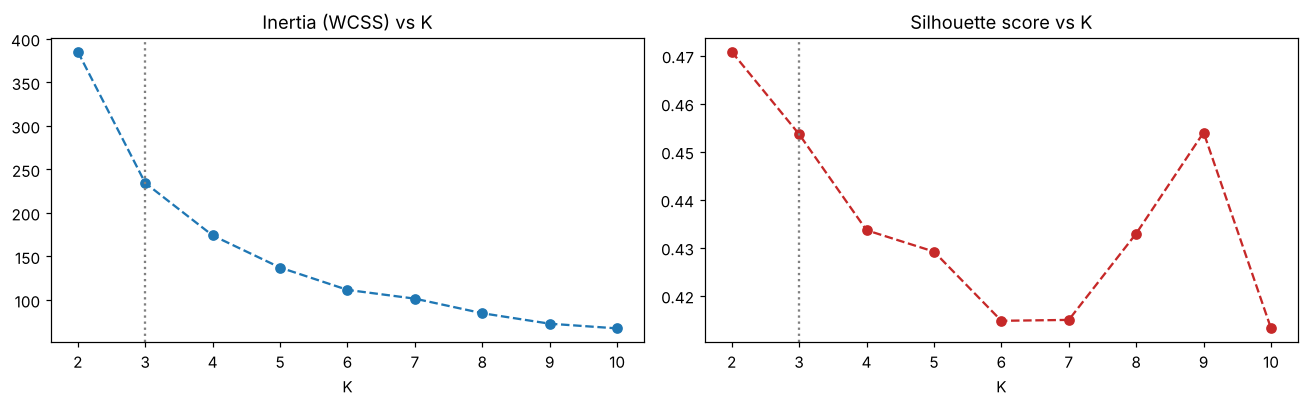

In [7]:
K_RANGE = range(2, 11)
inertias, silhouettes = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, init='random', random_state=9001, n_init=10).fit(X_scaled)
    inertias.append(km.inertia_); silhouettes.append(silhouette_score(X_scaled, km.labels_))
k_tbl = pd.DataFrame({'K': list(K_RANGE), 'Inertia': inertias, 'Silhouette': silhouettes})
k_tbl['Decrease from K-1'] = -k_tbl['Inertia'].diff()          # drop obtained by moving from K-1 to K clusters
max_drop_K = int(k_tbl.loc[k_tbl['Decrease from K-1'].idxmax(), 'K'])
display(k_tbl.round(3))
print('max_drop_K =', max_drop_K)
k_tbl.round(4).to_csv(MET_DIR / 'k_selection.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(k_tbl.K, k_tbl.Inertia, 'o--'); axes[0].axvline(max_drop_K, color='grey', ls=':'); axes[0].set_title('Inertia (WCSS) vs K'); axes[0].set_xlabel('K')
axes[1].plot(k_tbl.K, k_tbl.Silhouette, 'o--', color='#C62828'); axes[1].axvline(max_drop_K, color='grey', ls=':'); axes[1].set_title('Silhouette score vs K'); axes[1].set_xlabel('K')
plt.tight_layout(); plt.savefig(FIG_DIR / 'k_selection.png', bbox_inches='tight'); plt.show()

**Observation:** Inertia falls most sharply from K = 2 to K = 3 (a drop of 150.8, against 60.3 for the next step), so `max_drop_K = 3`. The silhouette score is highest at K = 2 (0.471), but K = 3 is close (0.454) and gives a more useful segmentation. Beyond K = 3 the gains flatten.

# Task 3: Build and Interpret the Clusters

- Build the final K-Means model using `KMeans()` with `n_clusters = max_drop_K`, `init = 'random'`, `random_state = 9001`, and `n_init = 10`
- Assign each observation to a cluster
- Display the number of observations in each cluster
- Inverse transform the cluster centroids back to the original feature scale
- Compare the centroid values to understand the differences between the three groups of cars
- Assign a meaningful and subjective label to each cluster based on engine size, horsepower, city mileage, and highway mileage

In [8]:
km = KMeans(n_clusters=max_drop_K, init='random', random_state=9001, n_init=10).fit(X_scaled)
X_clustered = X.assign(Cluster=km.labels_)
print('Cars per cluster:', {int(c): int(n) for c, n in zip(*np.unique(km.labels_, return_counts=True))})
centroids = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=X.columns).round(1)
# Subjective labels from the centroid profile (largest engines -> performance; best mileage -> economy)
order = centroids['horsepower'].sort_values().index
names = dict(zip(order, ['Economy', 'Mainstream', 'Performance'][:len(order)] if len(order) == 3 else [f'Group {i}' for i in range(len(order))]))
centroids['Segment'] = centroids.index.map(names); centroids['Cars'] = np.bincount(km.labels_)
X_clustered['Segment'] = X_clustered['Cluster'].map(names)
display(centroids.set_index('Segment'))
centroids.to_csv(MET_DIR / 'cluster_centroids.csv', index=False)

Cars per cluster: {0: 61, 1: 98, 2: 46}


,enginesize,horsepower,citympg,highwaympg,Cars
Segment,,,,,
Economy,95.2,67.3,33.1,39.0,61
Mainstream,120.2,98.9,23.7,29.3,98
Performance,183.2,164.1,17.9,23.0,46


**Observation:** The three centroids form a clear ladder. **Economy** (61 cars): engine size about 95, 67 hp, 33/39 mpg city/highway. **Mainstream** (98 cars): about 120, 99 hp, 24/29 mpg. **Performance** (46 cars): about 183, 164 hp, 18/23 mpg. Engine size and power rise together while fuel efficiency falls.

# Task 4: Visualise the Clusters
- Visualise the K-Means clusters using the original engine size and horsepower values
- Display the cluster centroids on the graph

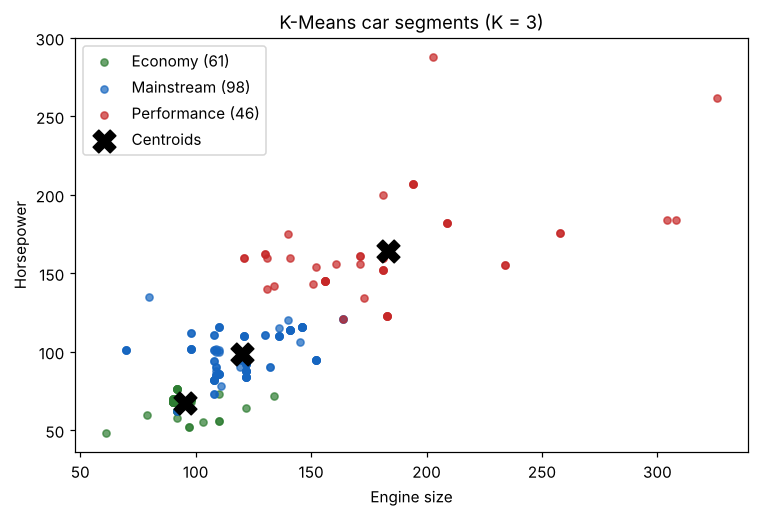

In [9]:
colors = {'Economy': '#2E7D32', 'Mainstream': '#1565C0', 'Performance': '#C62828'}
fig, ax = plt.subplots(figsize=(7, 4.8))
for seg, sub in X_clustered.groupby('Segment'):
    ax.scatter(sub['enginesize'], sub['horsepower'], s=22, alpha=0.7, color=colors.get(seg), label=f'{seg} ({len(sub)})')
ax.scatter(centroids['enginesize'], centroids['horsepower'], marker='X', s=220, color='black', label='Centroids')
ax.set_xlabel('Engine size'); ax.set_ylabel('Horsepower'); ax.set_title(f'K-Means car segments (K = {max_drop_K})'); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'clusters_engine_hp.png', bbox_inches='tight'); plt.show()

**Observation:** In engine-size versus horsepower space, the segments occupy three bands along a single diagonal. The performance segment is the most spread out, because it includes a few very large engines (over 250).

# Task 5: Visualise the Clusters Using t-SNE
- Apply t-SNE using `n_components = 2`, `random_state = 9001`, `perplexity = 30`, `init = 'pca'`, and `learning_rate = 'auto'`
- Visualise the K-Means clusters using the two t-SNE components

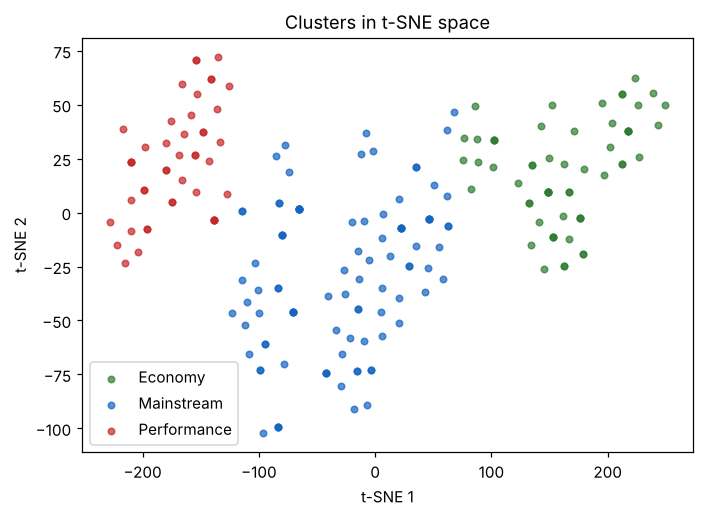

In [10]:
tsne = TSNE(n_components=2, random_state=9001, perplexity=30, init='pca', learning_rate='auto')
emb = tsne.fit_transform(X_scaled)
fig, ax = plt.subplots(figsize=(6.5, 4.8))
for seg in colors:
    m = (X_clustered['Segment'] == seg).values
    ax.scatter(emb[m, 0], emb[m, 1], s=18, alpha=0.7, color=colors[seg], label=seg)
ax.set_title('Clusters in t-SNE space'); ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2'); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'clusters_tsne.png', bbox_inches='tight'); plt.show()

**Observation:** t-SNE keeps the three segments mostly apart, with some contact between economy and mainstream cars. Many cars share identical specifications, so t-SNE shows them as tight point clumps.

# Task 6: Visualise the Clusters Using PCA
- Apply PCA with `n_components=2` to transform the scaled observations and scaled cluster centroids into two dimensions
- Visualise the K-Means clusters and their centroids using the two principal components

Variance explained by PC1, PC2: [0.837 0.115] | total 0.952


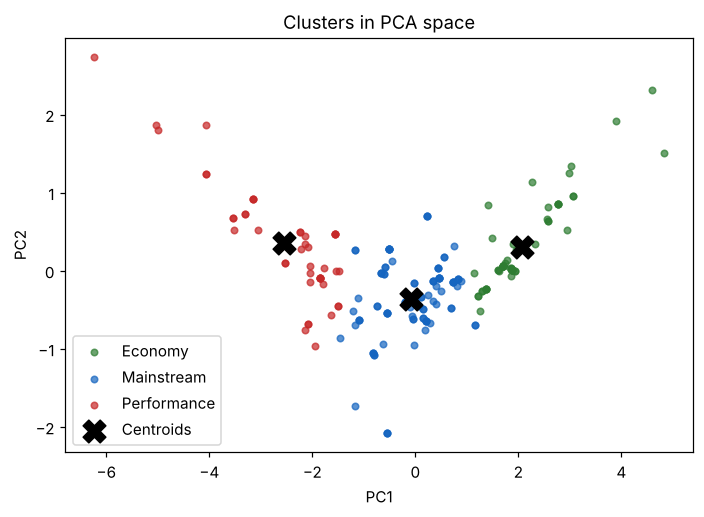

,enginesize,horsepower,citympg,highwaympg
PC1,-0.466,-0.505,0.515,0.513
PC2,0.701,0.291,0.469,0.452


In [11]:
pca = PCA(n_components=2).fit(X_scaled)
pcs, cpcs = pca.transform(X_scaled), pca.transform(km.cluster_centers_)
print('Variance explained by PC1, PC2:', pca.explained_variance_ratio_.round(3), '| total', pca.explained_variance_ratio_.sum().round(3))
fig, ax = plt.subplots(figsize=(6.5, 4.8))
for seg in colors:
    m = (X_clustered['Segment'] == seg).values
    ax.scatter(pcs[m, 0], pcs[m, 1], s=18, alpha=0.7, color=colors[seg], label=seg)
ax.scatter(cpcs[:, 0], cpcs[:, 1], marker='X', s=220, color='black', label='Centroids')
ax.set_title('Clusters in PCA space'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'clusters_pca.png', bbox_inches='tight'); plt.show()
display(pd.DataFrame(pca.components_, columns=X.columns, index=['PC1', 'PC2']).round(3))

**Observation:** PC1 alone explains 83.7% of the variance, and PC1 + PC2 explain 95.2%. PC1 is essentially a size-versus-efficiency axis: engine size and horsepower load negatively, both mileage figures positively. The clusters are cut along this one dominant axis, which is why the segmentation is so clean.

# Extension: How Stable Are the Segments?
K-Means depends on random initialisation. The model is refitted with 20 different seeds, and each labelling is compared with the one above using the Adjusted Rand Index (ARI: 1 = identical partition, 0 = chance agreement).

In [12]:
ari = [adjusted_rand_score(km.labels_, KMeans(n_clusters=max_drop_K, init='random', random_state=s, n_init=10).fit(X_scaled).labels_)
       for s in range(20)]
print(f'ARI across 20 seeds: mean {np.mean(ari):.3f}, min {np.min(ari):.3f}')
print('Distinct car specifications:', len(X.drop_duplicates()), 'of', len(X))

ARI across 20 seeds: mean 0.998, min 0.968
Distinct car specifications: 111 of 205


**Observation:** Across 20 random initialisations the partition barely changes (mean ARI 0.998, minimum 0.968), so the three segments are a stable property of the data rather than an accident of initialisation.

# Conclusion

| Segment | Cars | Engine size | Horsepower | City / highway mpg |
|---|---|---|---|---|
| Economy | 61 | 95 | 67 | 33 / 39 |
| Mainstream | 98 | 120 | 99 | 24 / 29 |
| Performance | 46 | 183 | 164 | 18 / 23 |

**Findings**
1. The largest inertia drop identifies K = 3, and the segments are stable across 20 initialisations (ARI ≥ 0.97).
2. One principal component carries 84% of the variance, so the cars lie largely along a single size-versus-efficiency axis, and the three segments are positions along it.
3. Nearly half the rows duplicate another car's specifications, which inflates apparent cluster density. Deduplicating would be worth checking in a production segmentation.

**Limitations:** Only four technical features, with no price, body type or brand. 205 cars from a single historical dataset.